In [12]:
# import modules/libraries:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root = Path("/rcp/rcp42/home/esotelo/Research/ScatteringDAS")
sys.path.insert(0, str(root / "py_files"))

from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from cnct_search import cnct_search

import DAS_processing as DASproc
import DAS_model_inversion as DASmi
import DAS_plots as DASplt
from cnct_search import cnct_search, submit_detached

from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import pickle

import numpy as np
import jin_pylib
from jin_pylib import Data2D_XT,ProcessUtil
from glob import glob

import scipy
import scipy.signal as scisig
from scipy.integrate import cumulative_trapezoid
from scipy.fft import fft, ifft, fftfreq
from scipy.signal import butter, filtfilt

%matplotlib inline
import copy

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
# medium parameters
vp=4291.584
vs=2407.92
rho=2600
wave='SS'


#source location
xs=82.0
ys=3700.25882
ts=1.9096

#fiber gauge length
gl=5

#estimate the critican angle
theta_c = np.rad2deg(np.arcsin(vs/vp))

Import Reflection data and source wavelet dictionary
*************************

In [14]:
#import scattering data
with open("./data/ref_stf_data.pkl", "rb") as f:
    ref_stf_data = pickle.load(f)

#inc_wave
dir_data=ref_stf_data['stf_data']
dist_source=ref_stf_data['stf_data']['mean_dist_source']

#Reflected data
ref_data=ref_stf_data['ref_data']

#includet fft in the ref_data
ref_data = DASmi.fft_traces(ref_data)

# select data based on cross-correlation thresholds
pos_cc_th=0.8
neg_cc_th=0.8
cc_th=(pos_cc_th, neg_cc_th)

ref_data = DASmi.select_DAS_traces(ref_data, cc_th)   # (positive, negative) cc thresholds

# trace weights
trace_weights=DASmi.calculate_trace_weight(ref_data)

#geometric factor
freqs=dir_data['stf_trace']['freqs']
alpha=0.5
#reflected
gfactor=DASmi.geometric_factor_ref(ref_data,freqs,gl,vs,alpha)
#direct
gd=DASmi.geometric_factor_dir(dir_data, gl, vs, alpha)

#update dictionary with geometric factors
ref_data.update({
    "Gr": gfactor['Gr'],
    "d_factor": gfactor['d_factor'],
    "freqs":gfactor['freqs'],
    "omega": gfactor['omega'],
    "weights":trace_weights
})

#addding weights for the direct data traces
#DASmi.add_lateral_weights(ref_data, gl)   # adds snr_lat, sigma2_lat, w_lat
DASmi.add_noise_weights(ref_data)   ; # was DASproc.add_noise_weights

#original direct data
dir_orig=copy.deepcopy(dir_data)

#zerophase low pass
DASmi.lowpass_tukey_zerophase_stf(dir_data, f_end=400, alpha=0.6);


Inversion test

In [15]:
#general parameters
path='./inv_results/RfromStf'

#inc data
inc_data=(dir_data['stf_trace'],gd['Gd'])
# medium parameters
medium=(vp,vs,rho,wave)
snr_min=7
groups = DASmi.trace_grouping(ref_data, snr_min=snr_min, medium=medium, crit_tol=1,
                                  user_idx_drop=[0, 1, 2, 3, 4])

search_mode='constrained'
grid='ratio_ct'
eps=0.06
search_space=((0.01,3.5), (1e-14, 1e-8))
nsearch=(50, 50)
cc='signed'
trace_opts = {"weight": "w_noise", "select": ("snr_noise", 7.0)}
shat_constraint=(0.2,3.0)
max_lag=35


 inversion with NO Q

In [18]:

#run 10,11,12,13  same as run 8 but with different search_space
output_file0='group0pos_stf'
groups[0]

output_file1='group0pre_stf'
groups[1]

output_file2='group1_stf'
groups[2]

output_file3='group2_stf'
groups[3]

output_file4='group3_stf'
groups[4]


#common parameters

search_param_cons=(search_mode, 
                   grid, 
                   eps, 
                   search_space,
                   nsearch, 
                   cc,
                   shat_constraint,
                   trace_opts,
                   max_lag)

#function=DASmi.cnct_searchR_obs()

names = [output_file0, output_file1, output_file2, output_file3, output_file4]

In [19]:
jobs = [submit_detached(cnct_search, ref_data, inc_data, groups[k],medium, search_param_cons,
                      DASmi.cnct_searchR_obs, names[k], out_root=path)
        for k in range(len(groups))]

submitted group0pos_stf (pid 3454796); log: inv_results/RfromStf/group0pos_stf/group0pos_stf.log
submitted group0pre_stf (pid 3454797); log: inv_results/RfromStf/group0pre_stf/group0pre_stf.log
submitted group1_stf (pid 3454810); log: inv_results/RfromStf/group1_stf/group1_stf.log
submitted group2_stf (pid 3454833); log: inv_results/RfromStf/group2_stf/group2_stf.log
submitted group3_stf (pid 3454834); log: inv_results/RfromStf/group3_stf/group3_stf.log


Plotting results

In [12]:
idx=0
run=names[idx]
dir=path+'/'+run
plot_file=dir+'/'+run+'.pkl'
print(plot_file)

./inv_results/RfromStf/group0pos_stf/group0pos_stf.pkl


./inv_results/RfromStf/group3_stf/group3_stf.pkl


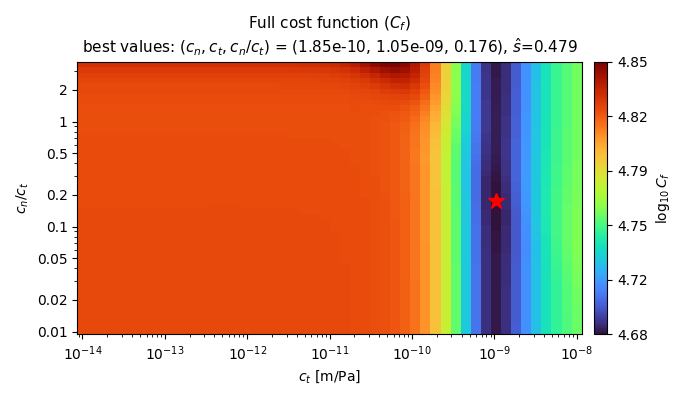

saved inv_results/RfromStf/group3_stf/other_plots/full_cost.png


(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Full cost function ($C_f$)\nbest values: $(c_n, c_t, c_n/c_t)$ = (1.85e-10, 1.05e-09, 0.176), $\\hat{s}$=0.479'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [32]:
#file to plot
idx=4
run=names[idx]
dir=path+'/'+run
plot_file=dir+'/'+run+'.pkl'
print(plot_file)

#options
which="full" # "full" or "constraint"
output="cost" # "cost" or "s_hat
plt.close('all')

DASplt.plot_cnct_search(plot_file, which="full", output="cost")
#DASplt.plot_cnct_search(plot_file, which="full", output="s_hat")
#fig, ax, picks = DASplt.pick_ratiosearch(plot_file, which="constraint", output="cost", load_existing=True)
#DASplt.plot_cnct_search(plot_file, which="constraint", output="cost_norm")
#DASplt.plot_cnct_search(plot_file, which="constraint", output="s_hat")

In [35]:
3/8

0.375

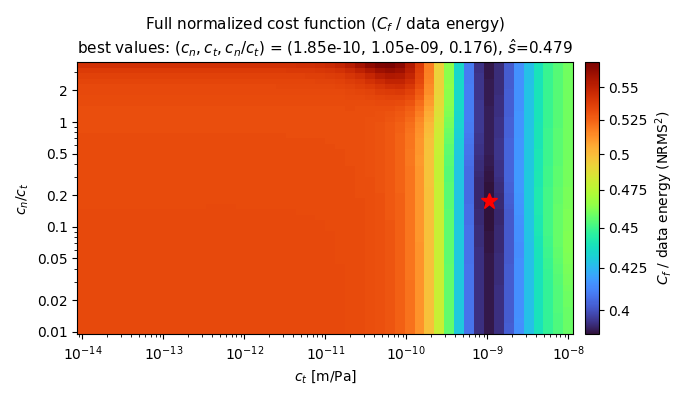

Button(description='Save figure', icon='save', style=ButtonStyle(), tooltip='save to inv_results/RfromStf/grou…

In [33]:
%matplotlib widget
fig, ax, picks = DASplt.pick_ratiosearch(plot_file, which="full", output="cost_norm", load_existing=False)


Plot waveforms

In [34]:
n_saved = DASplt.plot_waveform_picks(dir, ref_data, inc_data)

Inversion with  Q

In [ ]:
output_file0='group0pos_consQ'
output_file1='group0pre_consQ'
output_file2='group1_consQ'
output_file3='group2_consQ'
output_file4='group3_consQ'


fnames = [output_file0, output_file1, output_file2, output_file3,output_file4 ]

#Qparameters
Qlist=np.round(np.geomspace(25, 120, 11))
rd=dir_data["mean_dist_source"]

Qoption={"Q": Qlist, "rd": rd}


search_param_consQ=(search_mode,
                    grid, 
                    eps,
                    search_space,
                    nsearch,
                    cc,
                    shat_constraint,
                    trace_opts,
                    max_lag,
                    Qoption)

#e.g

In [ ]:

def run_one(k):
    # one group per process: same call as the serial runs
    cnct_search(ref_data, inc_data, groups[k], medium, search_param_consQ,
                DASmi.cnct_searchR_obs, fnames[k])
    return fnames[k]


with ProcessPoolExecutor(max_workers=5, mp_context=mp.get_context("fork")) as ex:
    for name in ex.map(run_one, range(5)):
        print("finished", name)


In [ ]:
#plots
k=4
file=path+'/'+fnames[k]+'/'+fnames[k]+'.pkl'
#options
which="full" # "full" or "constraint"
output="cost" # "cost" or "s_hat
plt.close('all')

DASplt.plot_cnct_search(file, which="full", output="cost")
DASplt.plot_cnct_search(file, which="constraint", output="cost")
DASplt.plot_cnct_search(file, which="full", output="Q_hat")
DASplt.plot_cnct_search(file, which="constraint", output="Q_hat")

In [ ]:
fig, ax, picks = DASplt.pick_ratiosearch(file, which="constraint", output="cost_norm", load_existing=False)

In [ ]:
dir=path+'/'+fnames[k]
n_saved = DASplt.plot_waveform_picks(dir, ref_data, inc_data)

Amplitude Spectrum inversion

In [ ]:
#No Q, No weighted spectrum all groups
search_mode_sp='full'
constraint_sp=None #constraining s_hat
freqband=(20,250)
misfit='log'
weights='ones'
beta=0.0


freq_opts = {"band":freqband,  # fit band (fmin, fmax) [Hz]
            "misfit": misfit,          # "log" (log amplitude, Q fixed by beta),
                                             # "log_Q" (log amplitude, Q estimated if beta=None),
                                              # "linear" (|D| - s|H|, Q fixed by beta)
            "W":      weights,         # frequency weight: "ones" = flat, "D2" = |D|^2
            "beta":   beta,            # 1/Q: 0.0 = no Q (only s); float = fixed, e.g. 1/60;
                                              # None = estimated (only with "log_Q")
            "rd":     None,           # direct (STF) path [m] = dir_data['mean_dist_source']
                                              # (86 m, V2); required when Q is estimated or beta > 0
            "a":      1.0}       

search_param_sp = (search_mode_sp,
                 grid, 
                 eps, 
                 search_space, 
                 nsearch,
                constraint_sp,
                trace_opts,
                freq_opts
                )


output_file0='sp_group0pos_W1'
groups[0]
output_file1='sp_group0pre_W1'
groups[1]

output_file2='sp_group1_W1'
groups[2]

output_file3='sp_group2_W1'
groups[3]

output_file4='sp_group3_W1'
groups[4]

folders=(output_file0, output_file1, output_file2,output_file3, output_file4)
path='./inv_results'
#eg. groups[0]. Run for all groups 
function=DASmi.cnct_search_Rspectrum(ref_data, inc_data,groups[0], medium, search_param_sp)

In [ ]:

#adding constraints

for f in folders:
    file=path+'/'+f+'/'+f+'.pkl'
    out = DASmi.Add_constrain_cntct_file(file,shat_constraint,None)

In [ ]:
#plots
k=1
file=path+'/'+folders[k]+'/'+folders[k]+'.pkl'
#options
which="full" # "full" or "constraint"
output="cost" # "cost" or "s_hat
plt.close('all')

DASplt.plot_cnct_search(file, which="constraint", output="cost")